In [1]:
# Chit 32: ECG anomaly detection with an autoencoder
# Step 1: Load the ECG data
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense

data = pd.read_csv("ecg.csv", header=None)
X = data.iloc[:, :-1].to_numpy(dtype="float32")
labels = data.iloc[:, -1].to_numpy()
normal_label = pd.Series(labels).value_counts().idxmax()
print("Most common class (assumed normal):", normal_label)

normal = X[labels == normal_label]
abnormal = X[labels != normal_label]
X_train, X_val = train_test_split(normal, test_size=0.2, random_state=42)

Most common class (assumed normal): 1.0


In [2]:
# Step 2: Scale the ECG features
scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = np.vstack([X_val, scaler.transform(abnormal)])
y_test = np.concatenate([np.zeros(len(X_val), dtype=int), np.ones(len(abnormal), dtype=int)])

In [3]:
# Step 3: Build and train the autoencoder
model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(32, activation="relu"),
    Dense(16, activation="relu"),
    Dense(32, activation="relu"),
    Dense(X_train.shape[1], activation="linear")
])
model.compile(optimizer="adam", loss="mse")
model.summary()
history = model.fit(X_train, X_train, epochs=10, batch_size=128, validation_split=0.1, verbose=0)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 32)                  │           4,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 32)                  │             544 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 140)                 │           4,620 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 10,204 (39.86 KB)

 Trainable params: 10,204 (39.86 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
# Step 4: Detect abnormal records
val_reconstruction = model.predict(X_val, verbose=0)
val_errors = np.mean(np.square(X_val - val_reconstruction), axis=1)
threshold = np.percentile(val_errors, 95)

test_reconstruction = model.predict(X_test, verbose=0)
test_errors = np.mean(np.square(X_test - test_reconstruction), axis=1)
y_pred = (test_errors > threshold).astype(int)
print("Reconstruction-error threshold:", threshold)
print("Actual abnormal records in test:", int(y_test.sum()))
print("Detected abnormal records:", int(y_pred.sum()))

Reconstruction-error threshold: 0.03335446
Actual abnormal records in test: 2079
Detected abnormal records: 1902


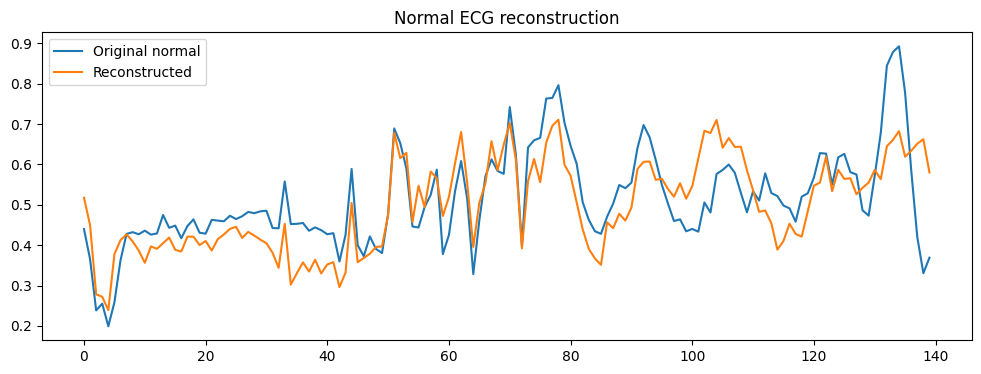

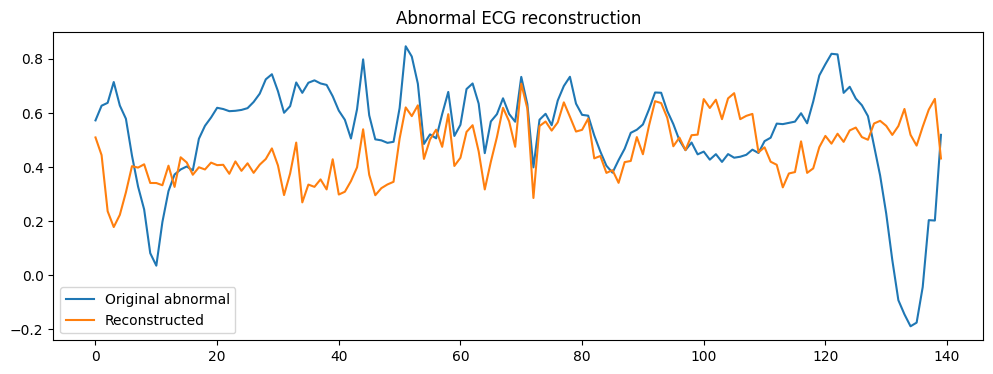

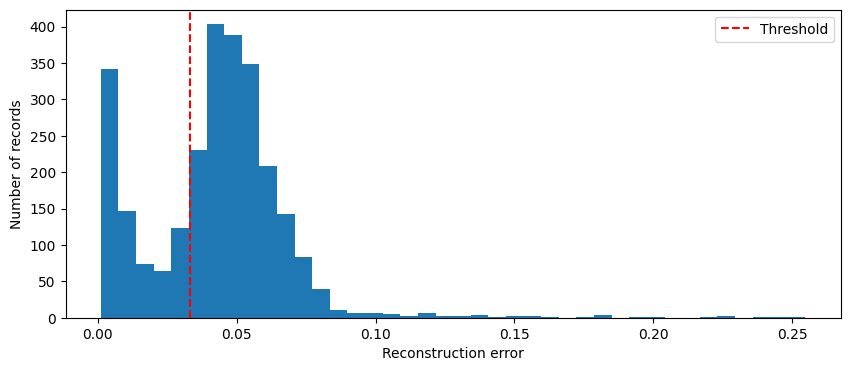

In [5]:
# Step 5: Plot sample signals and errors
normal_i = 0
abnormal_indices = np.where(y_test == 1)[0]
abnormal_i = int(abnormal_indices[0]) if len(abnormal_indices) else normal_i

plt.figure(figsize=(12, 4))
plt.plot(X_test[normal_i], label="Original normal")
plt.plot(test_reconstruction[normal_i], label="Reconstructed")
plt.title("Normal ECG reconstruction")
plt.legend()
plt.show()

if len(abnormal_indices):
    plt.figure(figsize=(12, 4))
    plt.plot(X_test[abnormal_i], label="Original abnormal")
    plt.plot(test_reconstruction[abnormal_i], label="Reconstructed")
    plt.title("Abnormal ECG reconstruction")
    plt.legend()
    plt.show()

plt.figure(figsize=(10, 4))
plt.hist(test_errors, bins=40)
plt.axvline(threshold, color="red", linestyle="--", label="Threshold")
plt.xlabel("Reconstruction error")
plt.ylabel("Number of records")
plt.legend()
plt.show()